# Consistency Models

## 1. Setup

Imports, device, random seed and a first look at MNIST, whose pixels are scaled
to $[-1, 1]$.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "system").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "system"))

import matplotlib.pyplot as plt
import numpy as np
import torch

from data import get_dataloader
from utils import get_device, set_seed

SEED = 42
set_seed(SEED)
device = get_device()
print("Device:", device)

[INFO] Seed set to 42
Device: cpu


Batch: (16, 1, 28, 28) | pixel range: (-1.0, 1.0)


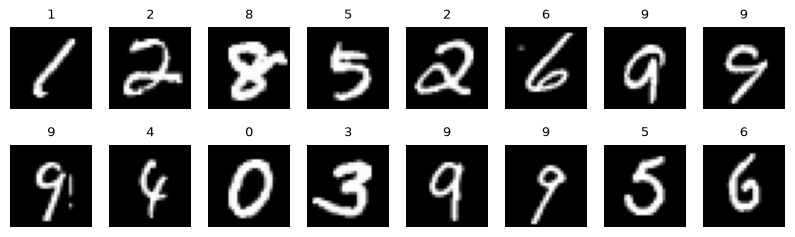

In [2]:
images, labels = next(iter(get_dataloader(batch_size=16, train=True, data_dir="./data")))
print("Batch:", tuple(images.shape), "| pixel range:", (images.min().item(), images.max().item()))

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow((image[0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(int(label), fontsize=9)
    ax.axis("off")
plt.show()

## 2. The teachers

### 2.1 Variance Exploding diffusion

In [3]:
# TODO

### 2.2 Rectified Flow

In [4]:
# TODO 

## 3. Consistency models

### 3.1 Consistency distillation

In [5]:
# TODO 

### 3.2 One-step and multistep sampling

In [6]:
# TODO 

In [7]:
# TODO 

### 3.3 Consistency training

In [8]:
# TODO 

## 4. Evaluation

We compare teachers and consistency models with a small classifier trained on
MNIST: FD-MNIST and the fraction of recognizable samples measure quality, and
the entropy of the predicted digits measures diversity. The seed is reset so
that the results do not depend on the previous sections. Small differences
with `results/` are expected, because the reference images and the noise of
multistep sampling are random.

In [9]:
from evaluation import compare
from evaluation.classifier import MNISTClassifier
from evaluation.metrics import (
    confident_fraction, extract_features, fd_mnist,
    label_distribution, label_entropy, max_label_entropy, predict_proba,
)
from evaluation.timing import benchmark_generation_time

%matplotlib inline
set_seed(SEED)

[INFO] Seed set to 42


### 4.1 The reference classifier

A small CNN trained with `system/training/classifier_training.py`. We load its
weights and check its accuracy on the test set.

In [10]:
classifier = compare.load_state(MNISTClassifier(), compare.CLASSIFIER_PATH, device)
print(classifier)
print(f"Parameters: {sum(p.numel() for p in classifier.parameters()):,}")

correct, total = 0, 0
with torch.no_grad():
    for x, y in get_dataloader(batch_size=1000, train=False, data_dir="./data"):
        correct += (classifier(x.to(device)).argmax(dim=1).cpu() == y).sum().item()
        total += y.numel()
print(f"Test accuracy: {100 * correct / total:.2f}%")

MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 421,642


Test accuracy: 99.00%


### 4.2 Why counting recognized digits is not enough

The classifier always picks a digit, even for images that are not digits.
Pure noise shows how often it does so with high confidence.

Real MNIST  recognized with confidence >= 0.9: 97.6%


Pure noise  recognized with confidence >= 0.9: 60.2%


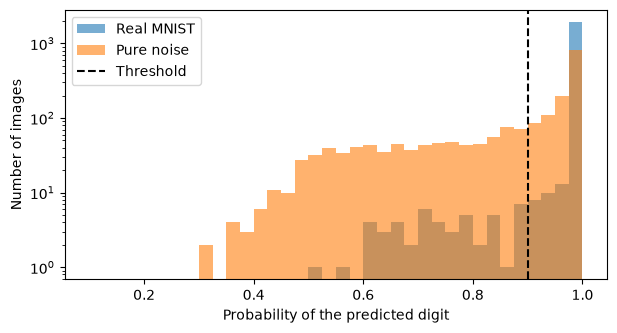

In [11]:
N_EVAL = compare.N_EVAL
real = compare.load_real_images(train=False, n=N_EVAL)
noise = torch.randn(N_EVAL, 1, 28, 28).clamp(-1.0, 1.0)

for name, images in [("Real MNIST", real), ("Pure noise", noise)]:
    fraction = confident_fraction(classifier, images, compare.CONFIDENCE_THRESHOLD)
    print(f"{name:11s} recognized with confidence >= {compare.CONFIDENCE_THRESHOLD}: {100 * fraction:.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0.1, 1.0, 37)
for name, images in [("Real MNIST", real), ("Pure noise", noise)]:
    confidence = predict_proba(classifier, images).max(dim=1).values.cpu().numpy()
    ax.hist(confidence, bins=bins, alpha=0.6, label=name)
ax.axvline(compare.CONFIDENCE_THRESHOLD, color="black", linestyle="--", label="Threshold")
ax.set_yscale("log")
ax.set_xlabel("Probability of the predicted digit")
ax.set_ylabel("Number of images")
ax.legend()
plt.show()

### 4.3 FD-MNIST

The Fréchet distance between the classifier features of generated and real
images (like FID, with our classifier instead of Inception). Real test images
and pure noise give two reference values.

In [12]:
reference = extract_features(classifier, compare.load_real_images(train=True, n=compare.N_REFERENCE))
print("Reference features:", reference.shape)

for name, images in [("Real MNIST", real), ("Pure noise", noise)]:
    print(f"{name:11s} FD-MNIST = {fd_mnist(classifier, images, reference):.1f}")

Reference features: (10000, 128)


Real MNIST  FD-MNIST = 47.0


Pure noise  FD-MNIST = 2929.6


### 4.4 Evaluating the generators

The VE teacher with 10 steps against CM-VE with 1, 2 and 4 steps, all starting
from the same noise.

In [13]:
models = {m.name: m for m in compare.MODELS}
selected = [models["VE teacher (diffusion)"]._replace(steps=[10]), models["CM-VE (CD)"]]
configs = [c for spec in selected for c in compare.build_configs(spec, device)]
x_T = configs[0].noise(N_EVAL, torch.Generator().manual_seed(42)).to(device)

samples = {}
for c in configs:
    samples[c.label] = compare.batched(c.generate, x_T)
    metrics, _ = compare.evaluate_samples(samples[c.label], classifier, reference)
    print(f"{c.label:30s} NFE={c.nfe:3d}  FD-MNIST={metrics['fd_mnist']:6.1f}  "
          f"recognizable={100 * metrics['recognizable']:5.1f}%  entropy={metrics['entropy']:.3f}")

VE teacher (diffusion) · 10 steps NFE= 20  FD-MNIST= 118.1  recognizable= 79.9%  entropy=2.253


CM-VE (CD) · 1 step            NFE=  1  FD-MNIST= 450.0  recognizable= 64.2%  entropy=2.186


CM-VE (CD) · 2 steps           NFE=  2  FD-MNIST= 386.6  recognizable= 68.4%  entropy=2.202


CM-VE (CD) · 4 steps           NFE=  4  FD-MNIST= 330.9  recognizable= 69.3%  entropy=2.206


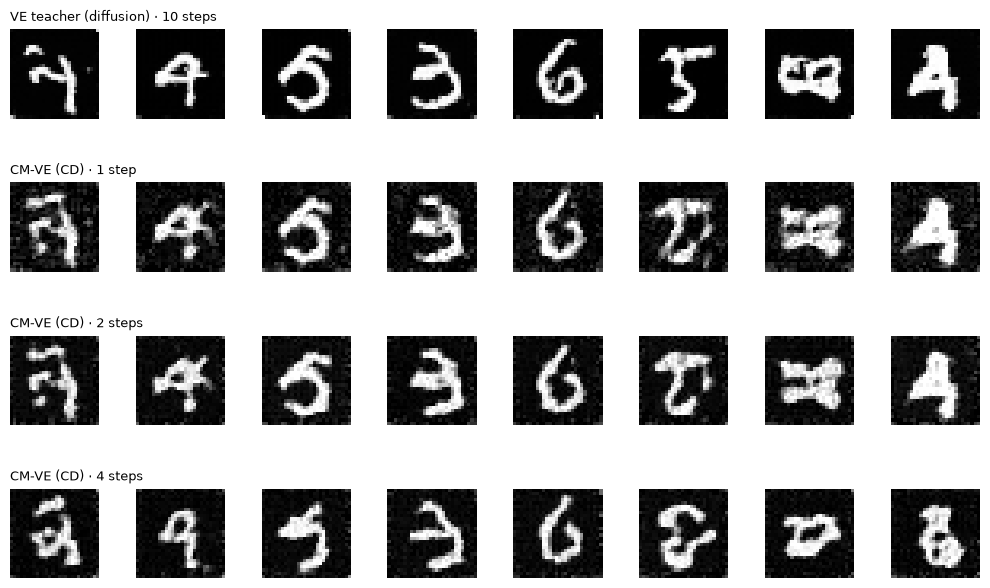

In [14]:
fig, axes = plt.subplots(len(samples), 8, figsize=(10, 1.6 * len(samples)))
for row, (label, images) in zip(axes, samples.items()):
    for ax, image in zip(row, images[:8]):
        ax.imshow((image[0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    row[0].set_title(label, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

### 4.5 Diversity

How often each digit is generated, and the entropy of that distribution
(maximum $\ln 10 \approx 2.30$).

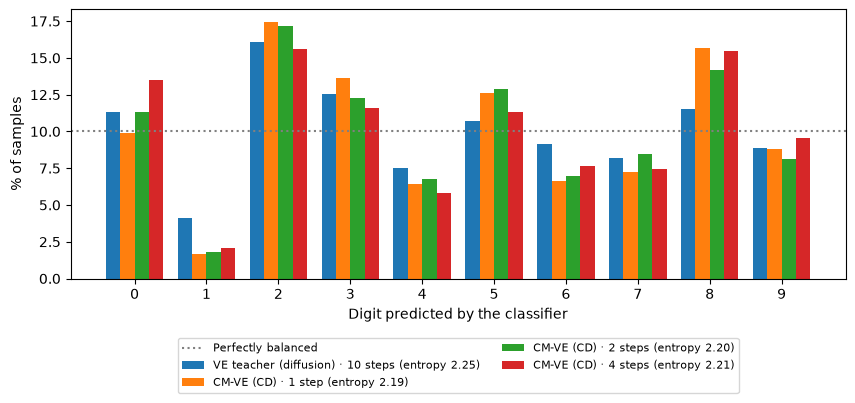

Maximum entropy: ln 10 = 2.303


In [15]:
digits = np.arange(10)
width = 0.8 / len(samples)
fig, ax = plt.subplots(figsize=(10, 3.5))
for i, (label, images) in enumerate(samples.items()):
    distribution = label_distribution(classifier, images).cpu()
    ax.bar(digits + i * width, 100 * distribution.numpy(), width,
           label=f"{label} (entropy {label_entropy(distribution):.2f})")
ax.axhline(10, color="gray", linestyle=":", label="Perfectly balanced")
ax.set_xticks(digits + 0.4 - width / 2, digits)
ax.set_xlabel("Digit predicted by the classifier")
ax.set_ylabel("% of samples")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()
print(f"Maximum entropy: ln 10 = {max_label_entropy():.3f}")

### 4.6 Sampling speed

Generation time as a function of the number of images $N$.

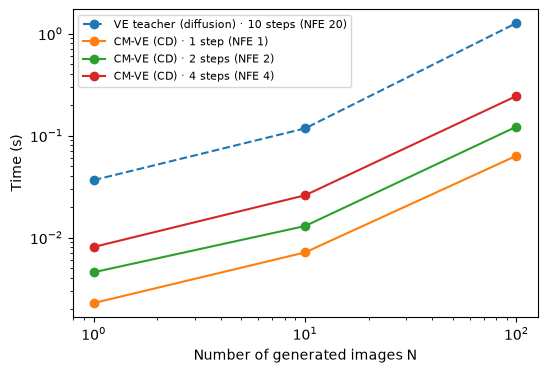

VE teacher (diffusion) · 10 steps  12.69 ms/image   speed-up vs. the 10-step teacher: x1.0
CM-VE (CD) · 1 step              0.63 ms/image   speed-up vs. the 10-step teacher: x20.0
CM-VE (CD) · 2 steps             1.22 ms/image   speed-up vs. the 10-step teacher: x10.4
CM-VE (CD) · 4 steps             2.45 ms/image   speed-up vs. the 10-step teacher: x5.2


In [16]:
sizes = [1, 10, 100]
timings = {
    c.label: benchmark_generation_time(lambda n, c=c: c.generate(c.noise(n).to(device)), sizes, n_repeats=3)
    for c in configs
}

fig, ax = plt.subplots(figsize=(6, 4))
for c in configs:
    ax.plot(sizes, [timings[c.label][n] for n in sizes], "--" if c.is_teacher else "-",
            marker="o", label=f"{c.label} (NFE {c.nfe})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of generated images N")
ax.set_ylabel("Time (s)")
ax.legend(fontsize=8)
plt.show()

n = max(sizes)
teacher = configs[0].label
for c in configs:
    t = timings[c.label][n]
    print(f"{c.label:30s} {1000 * t / n:6.2f} ms/image   speed-up vs. the 10-step teacher: x{timings[teacher][n] / t:.1f}")

### Putting it all together

`system/evaluation/compare.py` runs this evaluation for every model of the
project and writes the table and figures to `results/`. Run it from the root of the repository:

```bash
python system/evaluation/compare.py
```

## 5. Summary